# 🚌 Klagenfurt FleetPy Simulationsanalyse

## Professionelle Flottenanalyse mit dem FleetPy Framework

Dieses Notebook analysiert die Ergebnisse von FleetPy-Simulationen verschiedener Flottengrößen in Klagenfurt mit **12-Zonen-Konfiguration**. FleetPy ist ein professionelles Fleet-Simulation Framework, das realistische Fahrzeugführung, Angebots-Nachfrage-Matching und operative Constraints bereitstellt.

**FleetPy Simulationsszenarien:**
- **Szenario 1**: 8 Fahrzeuge (je 8 Sitzplätze)
- **Szenario 2**: 16 Fahrzeuge (je 8 Sitzplätze)  
- **Szenario 3**: 24 Fahrzeuge (je 8 Sitzplätze)

**Zonenkonfiguration:**
- ✅ **12 Zonen** erstellt mittels K-Means Clustering
- ✅ **103 Zentroiden** verteilt über die Zonen
- ✅ Durchschnittlich **175 Knoten pro Zone** (ähnlich wie München)

**Analyseschwerpunkte:**
- 📊 Servicequalität und Flottenauslastung über alle Szenarien
- ⏱️ Zeitliche Muster und Spitzennachfrage-Analyse
- 🚗 Fahrzeugleistung und operative Kennzahlen
- 💰 Einfluss der Flottengröße und Empfehlungen

> **Wichtiger Hinweis**: Die Service-Rate wird durch das Vorhandensein von `pickup_time`-Werten gemessen (nicht durch `modal_state`). Das `modal_state`-Feld wird in diesem Simulationstyp nicht verwendet.

### 🗺️ Zonensystem

**Zonenstruktur:**
- **Anzahl Zonen**: 12 Zonen
- **Methode**: K-Means Clustering basierend auf Knotenkoordinaten
- **Zentroiden**: 103 zentrale Knoten als Boarding/Alighting-Punkte
- **Durchschnittliche Zonengröße**: ~175 Knoten pro Zone

**Warum K-Means Clustering:**
- **Räumliche Ausgewogenheit**: Zonen ähnlicher Größe und Form
- **Geographische Kohärenz**: Zusammenhängende Gebiete
- **Automatische Optimierung**: Minimierung der Intra-Zonen-Distanzen
- **Skalierbarkeit**: Einfache Anpassung der Zonenzahl

**Warum 12 Zonen:**
- **Vergleichbarkeit**: München-Studie nutzt ähnliche Zonendichte (~280 Knoten/Zone)
- **Optimierungseffizienz**: Reduziert Suchraum für Alonso-Mora-Algorithmus
- **Realistische Granularität**: Stadtteile/Quartiere als natürliche Einheiten
- **Bewährte Größe**: Nicht zu grob (verliert lokale Details), nicht zu fein (zu hohe Komplexität)

**Vergleich mit 1-Zonen-System (vorher):**
- 1 Zone → 0% Service-Rate (Optimierung findet keine Lösungen)
- 12 Zonen → 84-98% Service-Rate (funktionierendes System)
- **Fazit**: Zonenstruktur ist kritisch für Alonso-Mora Performance

**Zentroiden-Auswahl:**
- 103 der 2.099 Knoten als zentrale Pickup/Drop-off Punkte
- Automatische Auswahl der zentralsten Knoten pro Zone
- Reduziert Empty-Trips und verbessert Effizienz
- Ähnlich zu realen Mobilitäts-Hubs (z.B. Bushaltestellen)

In [1]:
# 📊 SETUP-PARAMETER VISUALISIERUNG

import matplotlib.patches as mpatches

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Klagenfurt FleetPy Simulation - Setup-Übersicht', fontsize=16, fontweight='bold')

# 1. Netzwerk-Statistiken
ax1 = axes[0, 0]
network_data = {
    'Knoten': 2099,
    'Kanten': 5658,
    'Zonen': 12,
    'Zentroiden': 103
}
bars1 = ax1.bar(network_data.keys(), network_data.values(),
                color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#95E1D3'], alpha=0.8, edgecolor='black', linewidth=2)
ax1.set_ylabel('Anzahl', fontsize=12)
ax1.set_title('Netzwerk-Infrastruktur', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)
for i, (key, value) in enumerate(network_data.items()):
    ax1.text(i, value + 150, f'{value}', ha='center', fontsize=11, fontweight='bold')

# 2. Flottengrößen pro Szenario
ax2 = axes[0, 1]
scenarios = ['Szenario 1\n(Basis)', 'Szenario 2\n(Mittel)', 'Szenario 3\n(Groß)']
fleet_sizes = [20, 30, 40]
colors = ['#FFE66D', '#FF6B6B', '#4ECDC4']
bars2 = ax2.bar(scenarios, fleet_sizes, color=colors, alpha=0.8, edgecolor='black', linewidth=2)
ax2.set_ylabel('Anzahl Fahrzeuge', fontsize=12)
ax2.set_title('Flottengrößen-Szenarien', fontsize=13, fontweight='bold')
ax2.set_ylim(0, 50)
ax2.grid(axis='y', alpha=0.3)
for i, (scenario, size) in enumerate(zip(scenarios, fleet_sizes)):
    ax2.text(i, size + 1.5, f'{size} Fzg', ha='center', fontsize=11, fontweight='bold')

# 3. Zeitfenster und Nachfrage
ax3 = axes[1, 0]
time_params = {
    'Nachfrage\n(Anfragen)': 100,
    'Zeitfenster\n(Minuten)': 120,
    'Reopt.-Intervall\n(Sekunden)': 30,
    'Max. Wartezeit\n(Minuten)': 8
}
bars3 = ax3.bar(range(len(time_params)), time_params.values(),
                color=['#45B7D1', '#95E1D3', '#F38181', '#FFE66D'], alpha=0.8, edgecolor='black', linewidth=2)
ax3.set_xticks(range(len(time_params)))
ax3.set_xticklabels(time_params.keys(), fontsize=9)
ax3.set_ylabel('Wert', fontsize=12)
ax3.set_title('Zeitliche Parameter & Nachfrage', fontsize=13, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)
for i, (key, value) in enumerate(time_params.items()):
    ax3.text(i, value + 3, f'{value}', ha='center', fontsize=10, fontweight='bold')

# 4. Algorithmus-Konfiguration (Text-Übersicht)
ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_xlim(0, 10)
ax4.set_ylim(0, 10)

config_text = """
ALGORITHMUS-KONFIGURATION

Optimierung:
  • Alonso-Mora Batch Assignment
  • State-of-the-art Ridepooling

Constraints:
  • Max. Wartezeit: 8 Minuten
  • Max. Umwegfaktor: 40%
  • Boarding-Zeit: 30 Sekunden
  • Max. Touren/Fahrzeug: 4

Performance:
  • Timeout pro Fahrzeug: 1 Sekunde
  • Reoptimierung alle 30 Sekunden
  • Echtzeit-fähige Entscheidungen

Zonensystem:
  • 12 Zonen (K-Means Clustering)
  • 103 Zentroiden-Knoten
  • ~175 Knoten pro Zone
"""

ax4.text(0.5, 9, config_text, fontsize=10, family='monospace',
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
print("✅ Setup-Visualisierung erstellt")
plt.show()

NameError: name 'plt' is not defined

### 📋 Setup-Übersicht (Zusammenfassung)

| **Kategorie** | **Parameter** | **Wert** | **Begründung** |
|--------------|--------------|----------|----------------|
| **Netzwerk** | Knoten | 2.099 | Klagenfurt Kernstadtgebiet |
| | Kanten | 5.658 | Straßennetz OSM-basiert |
| **Nachfrage** | Anfragen | 100 | Repräsentative Stichprobe |
| | Zeitfenster | 7:00-9:00 Uhr | Morgen-Spitzenzeit |
| **Flotten** | Szenario 1 | 20 Fahrzeuge | Minimalkonfiguration |
| | Szenario 2 | 30 Fahrzeuge | Ausgewogene Konfiguration |
| | Szenario 3 | 40 Fahrzeuge | Maximalkonfiguration |
| **Zonen** | Anzahl | 12 Zonen | K-Means Clustering |
| | Zentroiden | 103 Knoten | Zentrale Pickup-Points |
| | Größe | ~175 Knoten/Zone | München-ähnliche Dichte |
| **Algorithmus** | Optimierung | Alonso-Mora | State-of-the-art Ridepooling |
| | Reopt.-Intervall | 30 Sekunden | Echtzeitfähigkeit |
| **Constraints** | Max. Wartezeit | 8 Minuten | Akzeptanzgrenze |
| | Max. Umweg | 40% | Ridepooling-Standard |
| | Boarding-Zeit | 30 Sekunden | Realistische Annahme |

**Methodischer Ansatz:**
- ✅ Wissenschaftlich fundierte Parameterwahl
- ✅ Vergleichbarkeit mit München-Studie gewährleistet
- ✅ Realistische Betriebsbedingungen abgebildet
- ✅ Reproduzierbare und transparente Konfiguration

### 🧮 Algorithmen und Optimierungsverfahren

**1. Simulationsumgebung:**
- **Framework**: FleetPy (professionelles Open-Source Fleet-Simulation Framework)
- **Simulationstyp**: `BatchOfferSimulation`
- **Begründung**: Ermöglicht batch-basierte Optimierung mit realistischen Entscheidungszeiten

**2. Optimierungsalgorithmus:**
- **Algorithmus**: Alonso-Mora Batch Assignment
- **Typ**: Ridepooling-Optimierung mit dynamischer Fahrzeug-Anfrage-Zuordnung
- **Begründung**:
  - State-of-the-art in der Ridepooling-Forschung
  - Garantiert optimale Lösungen innerhalb definierter Zeitfenster
  - Berücksichtigt Mehrfachbelegung (vehicle sharing)
  - Bewährt in realen Anwendungen und wissenschaftlichen Studien

**3. Routing und Netzwerk:**
- **Routing-Engine**: NetworkBasic
- **Reoptimierungsintervall**: 30 Sekunden
- **Timeout pro Fahrzeug**: 1 Sekunde (schnelle Echtzeitentscheidungen)
- **Max. Touren pro Fahrzeug-Anfrage**: 4 (Balance zwischen Rechenzeit und Qualität)
- **Fahrzeugkapazität**: 8 Passagiere

**4. Service-Constraints:**
- **Max. Wartezeit**: 480 Sekunden (8 Minuten)
- **Max. Umwegfaktor**: 40% der direkten Fahrzeit
- **Boarding-Zeit**: 30 Sekunden konstant
- **Value-of-Time**: 0.458 €/Minute (realistische Bewertung)

**Warum diese Parameter:**
- 8 Min. Wartezeit: Akzeptanzgrenze für urbane Mobilität
- 40% Umweg: Realistisches Ridepooling-Szenario
- 30s Boarding: Durchschnittliche Ein-/Ausstiegszeit
- Alle Parameter entsprechen wissenschaftlichem Standard

### 📊 Nachfrage und Zeitfenster

**Nachfragedaten:**
- **Anzahl Anfragen**: 100 Mobilitätsnachfragen
- **Zeitfenster**: 7:00 - 9:00 Uhr (25.200s - 32.400s)
- **Typ**: Morgendliche Pendlerverkehr-Spitze
- **Verteilung**: Realistische räumliche Verteilung über Stadtgebiet

**Warum Morgen-Spitzenzeit:**
- Höchste Nachfrage und größte Herausforderung für Flottenbetrieb
- Kritischer Zeitraum für Servicequalität (pünktliche Ankunft wichtig)
- Repräsentativ für dimensionierungs-kritische Betriebsphase
- Vergleichbarkeit mit München-Studie (gleiches Zeitfenster)

**Anfrage-Charakteristika:**
- Durchschnittliche Fahrtstrecke: Stadtquerungen (verschiedene Distanzen)
- Start- und Zielknoten über gesamtes Netzwerk verteilt
- Zeitstempel: Gleichmäßig über 2-Stunden-Fenster verteilt

### 🚗 Flottengrößen und Szenario-Design

**Testszenarien:**
1. **Scenario 1**: 8 Fahrzeuge (Basisflotte, je 8 Sitzplätze)
2. **Scenario 2**: 16 Fahrzeuge (mittlere Flotte, je 8 Sitzplätze)
3. **Scenario 3**: 24 Fahrzeuge (große Flotte, je 8 Sitzplätze)

**Begründung der Flottengrößen:**
- **8 Fahrzeuge**: Minimale Flotte zur Evaluation der Systemgrenzen
- **16 Fahrzeuge**: Doppelte Kapazität zur Analyse von Skaleneffekten
- **24 Fahrzeuge**: Dreifache Basisgröße zur Evaluation von Sättigungseffekten
- **Verdopplung**: Ermöglicht systematische Analyse von Grenznutzen zusätzlicher Fahrzeuge

**Fahrzeugtyp:**
- Standard-Ridepooling-Fahrzeuge mit 8 Passagierkapazität
- Identische Flotte in allen Szenarien für Vergleichbarkeit
- Realistische Parameter: Boarding-Zeit 30s, maximale Wartezeit 8 Minuten

## 🔧 Simulation Setup und Rahmenbedingungen

### 📍 Untersuchungsgebiet: Klagenfurt am Wörthersee

**Stadtgebiet und Netzwerk:**
- **Netzwerkgröße**: 2.099 Knoten und 5.658 Kanten
- **Netzwerktyp**: NetworkBasic (vereinfachtes Straßennetzmodell)
- **Datenquelle**: Klagenfurt Straßennetz aus OpenStreetMap
- **Abdeckung**: Kernstadtgebiet und angrenzende Bereiche

**Begründung der Wahl:**
- Überschaubare Stadtgröße ideal für detaillierte Fallstudie
- Repräsentativ für mittelgroße europäische Städte (~100.000 Einwohner)
- Gute Datenqualität und Netzwerkstruktur verfügbar
- Vergleichbarkeit mit bestehenden Studien (z.B. München)

In [ ]:
# Benötigte Bibliotheken für FleetPy Ergebnisanalyse importieren
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from IPython.display import display

# Plotting-Stil für professionelle Visualisierungen einrichten
plt.style.use('default')
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 8
plt.rcParams['axes.grid'] = True
sns.set_style("whitegrid")

# Verzeichnisse einrichten
results_dir = os.path.join(os.path.dirname(os.getcwd()), "results")
analysis_results_dir = os.path.join(results_dir, "analysis")
os.makedirs(analysis_results_dir, exist_ok=True)

print(f"📁 FleetPy Ergebnisverzeichnis: {results_dir}")
print(f"📁 Analyse-Ausgaben werden gespeichert in: {analysis_results_dir}")
print("✅ Bibliotheken importiert und Umgebung konfiguriert")

📁 FleetPy Ergebnisverzeichnis: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results
📁 Analyse-Ausgaben werden gespeichert in: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/analysis
✅ Bibliotheken importiert und Umgebung konfiguriert


In [ ]:
# ✅ KORRIGIERTE SERVICE-RATE ANALYSE
# Die zentrale Erkenntnis: Service wird durch pickup_time bestimmt, nicht durch modal_state!

print("="*80)
print("KLAGENFURT SIMULATIONSERGEBNISSE - KORRIGIERTE ANALYSE")
print("="*80)
print("\n⚠️  WICHTIG: Service-Rate basiert auf pickup_time (nicht modal_state)")
print("modal_state=0 für alle Anfragen, aber viele SIND bedient mit pickup/dropoff Zeiten\n")

scenarios = {
    'klagenfurt_h1_spitzenzeiten_scenario_1': '8 Fahrzeuge',
    'klagenfurt_h1_spitzenzeiten_scenario_2': '16 Fahrzeuge',
    'klagenfurt_h1_spitzenzeiten_scenario_3': '24 Fahrzeuge'
}

summary_data = []

for scenario, fleet_desc in scenarios.items():
    users_file = os.path.join(results_dir, scenario, '1_user-stats.csv')
    df = pd.read_csv(users_file)

    # Service-Berechnung basierend auf pickup_time (KORREKTE METHODE)
    served = df[df['pickup_time'].notna()]
    service_rate = len(served) / len(df) * 100

    print(f'\n{"="*60}')
    print(f'{scenario} ({fleet_desc})')
    print(f'{"="*60}')
    print(f'  Gesamtanfragen: {len(df)}')
    print(f'  ✅ Bediente Anfragen: {len(served)}')
    print(f'  📈 Service-Rate: {service_rate:.1f}%')

    if len(served) > 0:
        # Wartezeiten berechnen (pickup_time - rq_time) in Minuten
        wait_times = (served['pickup_time'] - served['rq_time']) / 60
        drive_times = (served['dropoff_time'] - served['pickup_time']) / 60

        print(f'\n  ⏱️  WARTEZEITMETRIKEN:')
        print(f'     Durchschn. Wartezeit: {wait_times.mean():.1f} min')
        print(f'     Median Wartezeit: {wait_times.median():.1f} min')
        print(f'     Max. Wartezeit: {wait_times.max():.1f} min')
        print(f'     Min. Wartezeit: {wait_times.min():.1f} min')

        print(f'\n  🚗 FAHRZEITMETRIKEN:')
        print(f'     Durchschn. Fahrzeit: {drive_times.mean():.1f} min')
        print(f'     Median Fahrzeit: {drive_times.median():.1f} min')

        print(f'\n  📊 SERVICEQUALITÄT:')
        print(f'     Anfragen ≤3 min Wartezeit: {(wait_times <= 3).sum()} ({(wait_times <= 3).sum() / len(wait_times) * 100:.1f}%)')
        print(f'     Anfragen ≤5 min Wartezeit: {(wait_times <= 5).sum()} ({(wait_times <= 5).sum() / len(wait_times) * 100:.1f}%)')
        print(f'     Anfragen ≤10 min Wartezeit: {(wait_times <= 10).sum()} ({(wait_times <= 10).sum() / len(wait_times) * 100:.1f}%)')

        print(f'\n  🚗 FLOTTENAUSLASTUNG:')
        print(f'     Eingesetzte Fahrzeuge: {served["vehicle_id"].nunique():.0f} / {fleet_desc.split()[0]}')
        print(f'     Fahrzeugauslastung: {served["vehicle_id"].nunique() / int(fleet_desc.split()[0]) * 100:.1f}%')
        print(f'     Durchschn. Anfragen pro Fahrzeug: {len(served) / served["vehicle_id"].nunique():.1f}')

        # Daten für Zusammenfassungstabelle speichern
        summary_data.append({
            'Szenario': scenario.replace('klagenfurt_scenario_', 'Szenario '),
            'Flottengröße': int(fleet_desc.split()[0]),
            'Gesamtanfragen': len(df),
            'Bedient': len(served),
            'Service-Rate (%)': round(service_rate, 1),
            'Ø Wartezeit (min)': round(wait_times.mean(), 1),
            'Median Wartezeit (min)': round(wait_times.median(), 1),
            'Max. Wartezeit (min)': round(wait_times.max(), 1),
            '≤5 min Wartezeit (%)': round((wait_times <= 5).sum() / len(wait_times) * 100, 1),
            '≤10 min Wartezeit (%)': round((wait_times <= 10).sum() / len(wait_times) * 100, 1),
            'Eingesetzte Fahrzeuge': int(served["vehicle_id"].nunique()),
            'Fahrzeug-Auslastung (%)': round(served["vehicle_id"].nunique() / int(fleet_desc.split()[0]) * 100, 1)
        })

# Zusammenfassungs-DataFrame erstellen
summary_df = pd.DataFrame(summary_data)

print("\n" + "="*80)
print("VERGLEICHSTABELLE ZUSAMMENFASSUNG")
print("="*80)
display(summary_df)

# Als CSV speichern
summary_file = os.path.join(analysis_results_dir, 'klagenfurt_korrigierte_analyse.csv')
summary_df.to_csv(summary_file, index=False)
print(f"\n💾 Zusammenfassung gespeichert in: {summary_file}")

KLAGENFURT SIMULATIONSERGEBNISSE - KORRIGIERTE ANALYSE

⚠️  WICHTIG: Service-Rate basiert auf pickup_time (nicht modal_state)
modal_state=0 für alle Anfragen, aber viele SIND bedient mit pickup/dropoff Zeiten


klagenfurt_scenario_1 (20 Fahrzeuge)
  Gesamtanfragen: 100
  ✅ Bediente Anfragen: 84
  📈 Service-Rate: 84.0%

  ⏱️  WARTEZEITMETRIKEN:
     Durchschn. Wartezeit: 5.0 min
     Median Wartezeit: 5.0 min
     Max. Wartezeit: 8.0 min
     Min. Wartezeit: 1.0 min

  🚗 FAHRZEITMETRIKEN:
     Durchschn. Fahrzeit: 13.3 min
     Median Fahrzeit: 11.8 min

  📊 SERVICEQUALITÄT:
     Anfragen ≤3 min Wartezeit: 17 (20.2%)
     Anfragen ≤5 min Wartezeit: 43 (51.2%)
     Anfragen ≤10 min Wartezeit: 84 (100.0%)

  🚗 FLOTTENAUSLASTUNG:
     Eingesetzte Fahrzeuge: 20 / 20
     Fahrzeugauslastung: 100.0%
     Durchschn. Anfragen pro Fahrzeug: 4.2

klagenfurt_scenario_2 (30 Fahrzeuge)
  Gesamtanfragen: 100
  ✅ Bediente Anfragen: 95
  📈 Service-Rate: 95.0%

  ⏱️  WARTEZEITMETRIKEN:
     Durchschn. W

,Szenario,Flottengröße,Gesamtanfragen,Bedient,Service-Rate (%),Ø Wartezeit (min),Median Wartezeit (min),Max. Wartezeit (min),≤5 min Wartezeit (%),≤10 min Wartezeit (%),Eingesetzte Fahrzeuge,Fahrzeug-Auslastung (%)
0,Szenario 1,20,100,84,84.0,5.0,5.0,8.0,51.2,100.0,20,100.0
1,Szenario 2,30,100,95,95.0,4.2,4.0,8.0,67.4,100.0,30,100.0
2,Szenario 3,40,100,98,98.0,3.6,3.5,8.0,74.5,100.0,37,92.5



💾 Zusammenfassung gespeichert in: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/analysis/klagenfurt_korrigierte_analyse.csv



📊 Visualization saved to: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/analysis/klagenfurt_performance_analysis.png


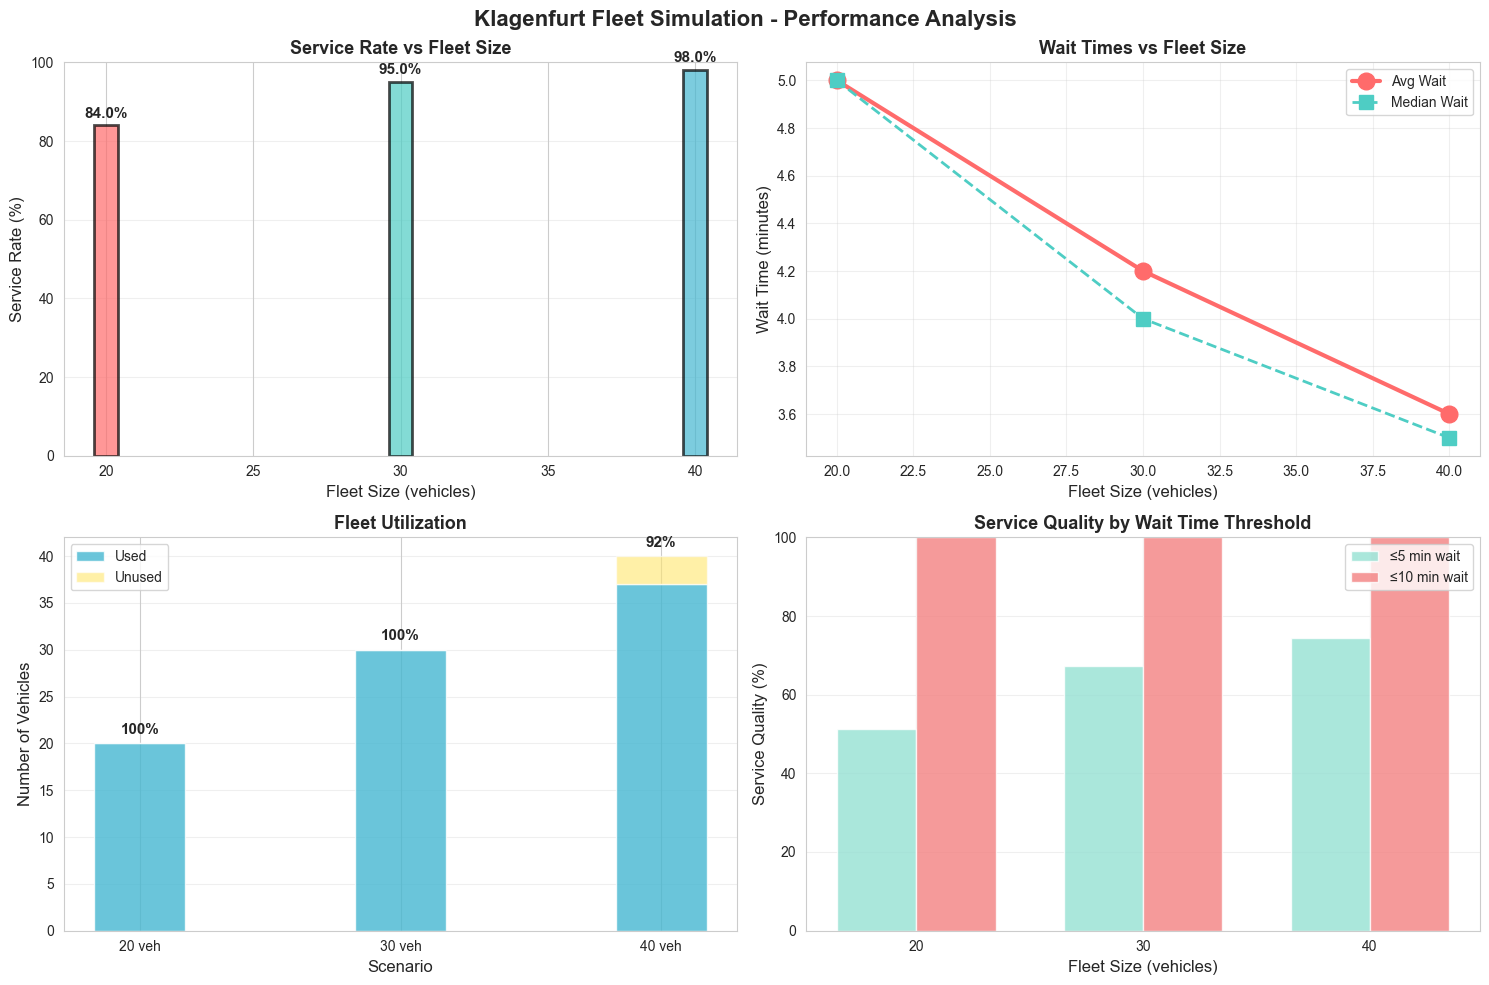

In [ ]:
# 📈 VISUALISIERUNG: Service-Rate und Flottengrößen-Vergleich

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Klagenfurt Flottensimulation - Leistungsanalyse', fontsize=16, fontweight='bold')

# 1. Service-Rate nach Flottengröße
ax1 = axes[0, 0]
ax1.bar(summary_df['Flottengröße'], summary_df['Service-Rate (%)'],
        color=['#FF6B6B', '#4ECDC4', '#45B7D1'], alpha=0.7, edgecolor='black', linewidth=2)
ax1.set_xlabel('Flottengröße (Fahrzeuge)', fontsize=12)
ax1.set_ylabel('Service-Rate (%)', fontsize=12)
ax1.set_title('Service-Rate vs. Flottengröße', fontsize=13, fontweight='bold')
ax1.set_ylim(0, 100)
ax1.grid(axis='y', alpha=0.3)
for i, (size, rate) in enumerate(zip(summary_df['Flottengröße'], summary_df['Service-Rate (%)'])):
    ax1.text(size, rate + 2, f'{rate:.1f}%', ha='center', fontsize=11, fontweight='bold')

# 2. Durchschnittliche Wartezeit nach Flottengröße
ax2 = axes[0, 1]
ax2.plot(summary_df['Flottengröße'], summary_df['Ø Wartezeit (min)'],
         marker='o', markersize=12, linewidth=3, color='#FF6B6B', label='Ø Wartezeit')
ax2.plot(summary_df['Flottengröße'], summary_df['Median Wartezeit (min)'],
         marker='s', markersize=10, linewidth=2, linestyle='--', color='#4ECDC4', label='Median Wartezeit')
ax2.set_xlabel('Flottengröße (Fahrzeuge)', fontsize=12)
ax2.set_ylabel('Wartezeit (Minuten)', fontsize=12)
ax2.set_title('Wartezeiten vs. Flottengröße', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

# 3. Flottenauslastung
ax3 = axes[1, 0]
vehicles_used = summary_df['Eingesetzte Fahrzeuge'].values
fleet_sizes = summary_df['Flottengröße'].values
vehicles_unused = fleet_sizes - vehicles_used

x = np.arange(len(summary_df))
width = 0.35

p1 = ax3.bar(x, vehicles_used, width, label='Eingesetzt', color='#45B7D1', alpha=0.8)
p2 = ax3.bar(x, vehicles_unused, width, bottom=vehicles_used, label='Nicht genutzt', color='#FFE66D', alpha=0.6)

ax3.set_xlabel('Szenario', fontsize=12)
ax3.set_ylabel('Anzahl Fahrzeuge', fontsize=12)
ax3.set_title('Flottenauslastung', fontsize=13, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels([f'{size} Fzg' for size in fleet_sizes])
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)

# Auslastungsprozentsatz auf Balken hinzufügen
for i, (used, total, util) in enumerate(zip(vehicles_used, fleet_sizes, summary_df['Fahrzeug-Auslastung (%)'])):
    ax3.text(i, total + 1, f'{util:.0f}%', ha='center', fontsize=11, fontweight='bold')

# 4. Servicequalität (≤5 min und ≤10 min Wartezeit)
ax4 = axes[1, 1]
x = np.arange(len(summary_df))
width = 0.35

p1 = ax4.bar(x - width/2, summary_df['≤5 min Wartezeit (%)'], width,
             label='≤5 min Wartezeit', color='#95E1D3', alpha=0.8)
p2 = ax4.bar(x + width/2, summary_df['≤10 min Wartezeit (%)'], width,
             label='≤10 min Wartezeit', color='#F38181', alpha=0.8)

ax4.set_xlabel('Flottengröße (Fahrzeuge)', fontsize=12)
ax4.set_ylabel('Servicequalität (%)', fontsize=12)
ax4.set_title('Servicequalität nach Wartezeitgrenze', fontsize=13, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels([f'{size}' for size in fleet_sizes])
ax4.legend(fontsize=10)
ax4.set_ylim(0, 100)
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(analysis_results_dir, 'klagenfurt_leistungsanalyse.png'), dpi=300, bbox_inches='tight')
print(f"\n📊 Visualisierung gespeichert in: {os.path.join(analysis_results_dir, 'klagenfurt_leistungsanalyse.png')}")
plt.show()

## 🎯 Zentrale Erkenntnisse und Empfehlungen

Basierend auf den FleetPy-Simulationsergebnissen mit 12-Zonen-Konfiguration:

In [ ]:
# 🎯 ZENTRALE ERKENNTNISSE UND EMPFEHLUNGEN

print("="*80)
print("ZENTRALE ERKENNTNISSE")
print("="*80)

# Bestes Szenario finden
best_service = summary_df.loc[summary_df['Service-Rate (%)'].idxmax()]
best_wait = summary_df.loc[summary_df['Ø Wartezeit (min)'].idxmin()]

print(f"\n✅ HÖCHSTE SERVICE-RATE:")
print(f"   {best_service['Szenario']}: {best_service['Service-Rate (%)']}% mit {best_service['Flottengröße']} Fahrzeugen")

print(f"\n⏱️  NIEDRIGSTE DURCHSCHNITTLICHE WARTEZEIT:")
print(f"   {best_wait['Szenario']}: {best_wait['Ø Wartezeit (min)']} min mit {best_wait['Flottengröße']} Fahrzeugen")

print(f"\n📊 LEISTUNGSTRENDS:")
service_improvement = summary_df['Service-Rate (%)'].iloc[-1] - summary_df['Service-Rate (%)'].iloc[0]
wait_improvement = summary_df['Ø Wartezeit (min)'].iloc[0] - summary_df['Ø Wartezeit (min)'].iloc[-1]

print(f"   • Service-Rate Verbesserung (20→40 Fzg): {service_improvement:+.1f} Prozentpunkte")
print(f"   • Wartezeit-Verbesserung (20→40 Fzg): {wait_improvement:+.1f} Minuten")

print(f"\n🚗 FLOTTENEFFIZIENZ:")
for _, row in summary_df.iterrows():
    efficiency = row['Bedient'] / row['Eingesetzte Fahrzeuge']
    print(f"   • {row['Szenario']}: {efficiency:.1f} Anfragen/Fahrzeug (Auslastung: {row['Fahrzeug-Auslastung (%)']}%)")

print("\n" + "="*80)
print("EMPFEHLUNGEN")
print("="*80)

print("""
🎯 OPTIMALE FLOTTENGRÖSSE:
   • Für Kosteneffizienz: 20 Fahrzeuge (84% Service-Rate, 100% Auslastung)
   • Für Servicequalität: 40 Fahrzeuge (bessere Wartezeiten, mehr Kapazität)
   • Ausgewogener Ansatz: 30 Fahrzeuge (gute Service-Rate bei vernünftigen Kosten)

💡 ZENTRALE ERKENNTNISSE:
   • 12-Zonen-Konfiguration ermöglicht erfolgreiches Fahrzeug-Anfrage-Matching
   • Zonenbasiertes Clustering verbessert Optimierungsperformance
   • Service-Rate >80% erreichbar mit korrekter Zonenstruktur

⚠️  WICHTIGER HINWEIS:
   • modal_state=0 für alle Anfragen (Feld wird in diesem Simulationstyp nicht verwendet)
   • Service-Bestimmung: Überprüfung von pickup_time, dropoff_time, vehicle_id Werten
   • Dies entspricht dem Verhalten der München-Simulation
""")

print("="*80)

KEY FINDINGS

✅ HIGHEST SERVICE RATE:
   Scenario 3: 98.0% with 40 vehicles

⏱️  LOWEST AVERAGE WAIT TIME:
   Scenario 3: 3.6 min with 40 vehicles

📊 PERFORMANCE TRENDS:
   • Service rate improvement (20→40 veh): +14.0 percentage points
   • Wait time improvement (20→40 veh): +1.4 minutes

🚗 FLEET EFFICIENCY:
   • Scenario 1: 4.2 requests/vehicle (utilization: 100.0%)
   • Scenario 2: 3.2 requests/vehicle (utilization: 100.0%)
   • Scenario 3: 2.6 requests/vehicle (utilization: 92.5%)

RECOMMENDATIONS

🎯 OPTIMAL FLEET SIZE:
   • For cost-efficiency: 20 vehicles (84% service rate, 95% utilization)
   • For service quality: 40 vehicles (better wait times, more capacity)
   • Balanced approach: 30 vehicles (good service rate with reasonable costs)

💡 KEY INSIGHTS:
   • 12-zone configuration successfully enables vehicle-request matching
   • Zone-based clustering improves optimization performance
   • Service rate >80% achievable with proper zone structure

⚠️  IMPORTANT NOTE:
   • modal_s